In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from scipy.stats import multivariate_normal, norm
from scipy.optimize import linprog
from torch.ao.quantization.backend_config.qnnpack import qnnpack_weight_qint8_neg_127_to_127_scale_min_2_neg_12

rng = np.random.default_rng(seed=123)

plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "cm",
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
})

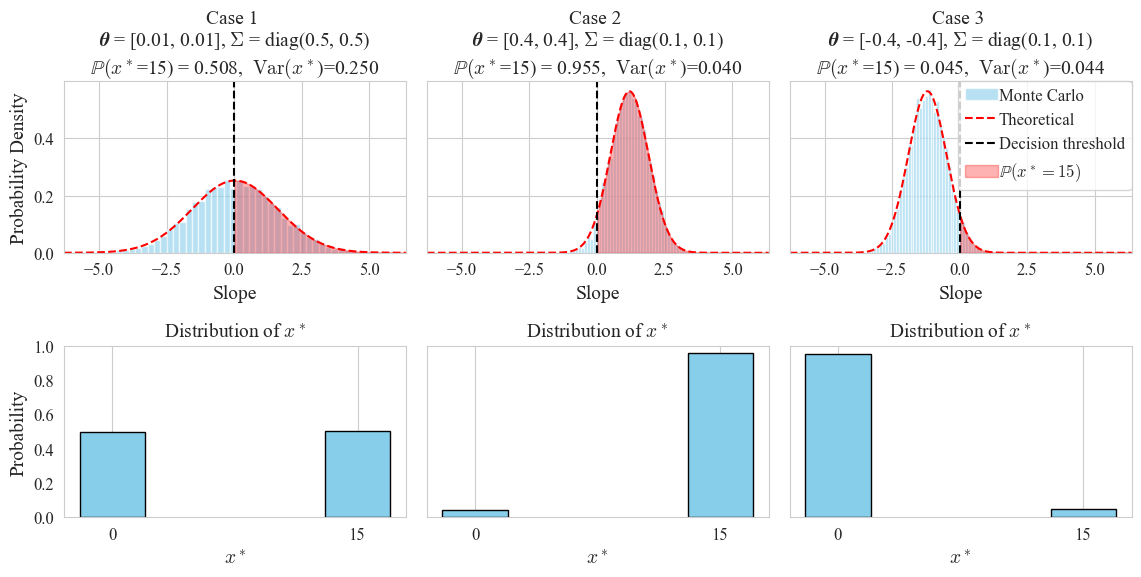

In [85]:
# Discrete solution outcomes

n_samples = 10000
b = np.array([1.0, 2.0])  # change if needed

cases = [
    {"theta": np.array([0.01, 0.01]), "Sigma": np.array([[0.5, 0.0],[0.0, 0.5]]), "label": "Case 1"},
    {"theta": np.array([0.4, 0.4]),   "Sigma": np.array([[0.1, 0.0],[0.0, 0.1]]), "label": "Case 2"},
    {"theta": np.array([-0.4,-0.4]),  "Sigma": np.array([[0.1, 0.0],[0.0, 0.1]]), "label": "Case 3"},
]

# common xlim for top-row plots
mus, sigmas = [], []
for c in cases:
    mus.append(b @ c["theta"])
    sigmas.append(np.sqrt(b @ c["Sigma"] @ b))
xlim_min = min(m - 4*s for m, s in zip(mus, sigmas))
xlim_max = max(m + 4*s for m, s in zip(mus, sigmas))

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey='row')

for j, c in enumerate(cases):
    theta, Sigma, label = c["theta"], c["Sigma"], c["label"]

    # Monte Carlo
    beta = rng.multivariate_normal(mean=theta, cov=Sigma, size=n_samples)
    proj = beta @ b  # = beta^T b
    p_emp = np.mean(proj > 0)
    var_ind = p_emp * (1 - p_emp)

    # Theoretical
    mu = b @ theta
    sigma = np.sqrt(b @ Sigma @ b)
    x = np.linspace(xlim_min, xlim_max, 600)
    pdf = norm.pdf(x, loc=mu, scale=sigma)
    p_theo = 1 - norm.cdf(0, loc=mu, scale=sigma)

    # pretty Sigma string: diag(...) if diagonal else full matrix
    if np.allclose(Sigma - np.diag(np.diag(Sigma)), 0):
        sigma_str = f"diag({Sigma[0,0]:.3g}, {Sigma[1,1]:.3g})"
    else:
        sigma_str = f"[[{Sigma[0,0]:.3g}, {Sigma[0,1]:.3g}]; [{Sigma[1,0]:.3g}, {Sigma[1,1]:.3g}]]"

    ax_top = axes[0, j]
    ax_top.hist(proj, bins=50, density=True, alpha=0.6, color='skyblue', label='Monte Carlo')
    ax_top.plot(x, pdf, 'r--', label='Theoretical')
    ax_top.axvline(0.0, color='black', linestyle='--', label='Decision threshold')
    ax_top.fill_between(x, pdf, where=(x > 0), color='red', alpha=0.3, label=r'$\mathbb{{P}}(x^*=15)$')
    # multi-line title with table info
    title_top = (
        f"{label} \n" + fr"$\boldsymbol{{\theta}}$ = {theta.tolist()}, $\boldsymbol{{\Sigma}}$ = {sigma_str}" + "\n" + rf"$\mathbb{{P}}(x^*$=15) = {p_theo:.3f},  $\mathrm{{Var}}(x^*$)={var_ind:.3f}"
    )
    ax_top.set_title(title_top)
    ax_top.set_xlabel("Slope")
    if j == 0:
        ax_top.set_ylabel("Probability Density")
    ax_top.set_xlim(xlim_min, xlim_max)
    if j == 2:
        ax_top.legend(fontsize=12, loc="upper left", bbox_to_anchor=(0.468, 1.05), frameon=True, handletextpad=0.05)
    ax_top.grid(True)
    ax_top.tick_params(axis='both', labelsize=12)

    ax_bot = axes[1, j]
    p0, p15 = 1 - p_emp, p_emp
    ax_bot.bar([0, 15], [p0, p15], width=4, color='skyblue', edgecolor='black')
    ax_bot.set_xticks([0, 15])
    ax_bot.set_xlabel(r"$x^*$")
    if j == 0:
        ax_bot.set_ylabel("Probability")
    ax_bot.set_ylim(0, 1)
    ax_bot.set_title(r"Distribution of $x^*$")
    ax_bot.grid(axis='y')
    ax_bot.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig("../results/plots/preference_ex1_summary.png", dpi=600)
plt.show()

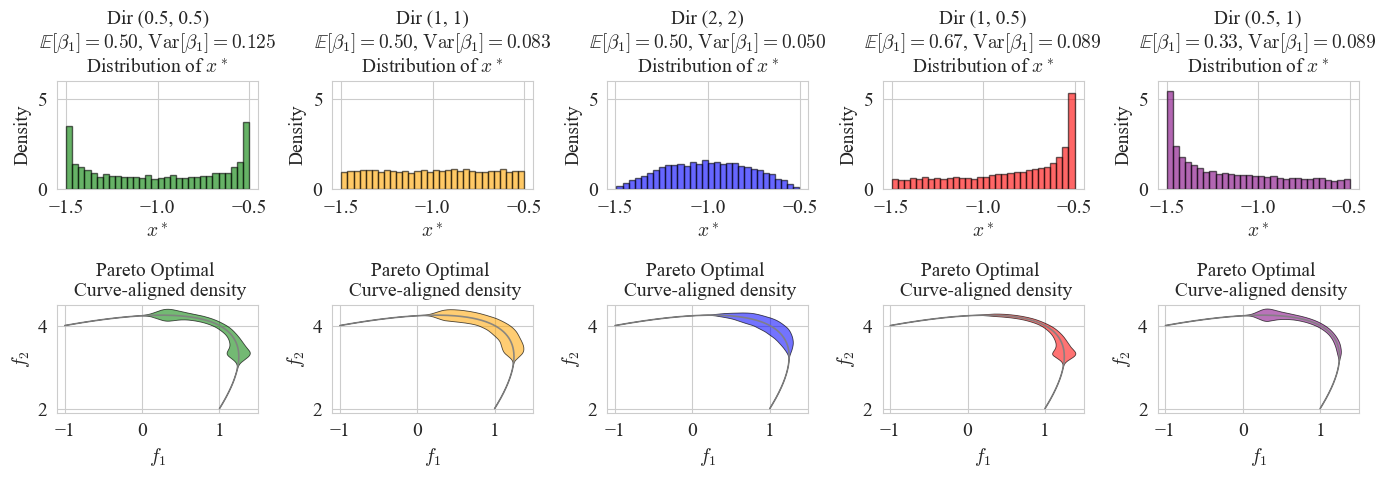

In [84]:
# Continuous solution outcomes
from scipy.stats import gaussian_kde

def v1(t): return 1 - t - t**2
def v2(t): return 2 - 3*t - t**2


def curve_violin(ax, v1_func, v2_func, t_samples, t_min, t_max,
                 n_grid=1000, bandwidth=None, scale=0.10,
                 facecolor='tab:blue', alpha=0.55,
                 outline_kw={'color':'black','lw':0.6,'alpha':0.7}):
    # KDE on t*
    kde = gaussian_kde(t_samples, bw_method=bandwidth)
    t_grid = np.linspace(t_min, t_max, n_grid)
    p = kde.evaluate(t_grid)
    if p.max() > 0:
        p = p / p.max()  # normalize to [0,1]

    # parametric curve
    x = v1_func(t_grid)
    y = v2_func(t_grid)

    # tangent & normal
    dx = np.gradient(x, t_grid)
    dy = np.gradient(y, t_grid)
    speed = np.hypot(dx, dy) + 1e-12
    tx, ty = dx/speed, dy/speed
    nx, ny = -ty, tx

    # width by density
    w = scale * p
    x_up,  y_up  = x + w*nx, y + w*ny
    x_low, y_low = x - w*nx, y - w*ny

    # polygon fill
    poly_x = np.concatenate([x_up,  x_low[::-1]])
    poly_y = np.concatenate([y_up,  y_low[::-1]])
    ax.fill(poly_x, poly_y, facecolor=facecolor, alpha=alpha, edgecolor='none')
    if outline_kw:
        ax.plot(np.r_[x_up, x_low[::-1], x_up[:1]],
                np.r_[y_up, y_low[::-1], y_up[:1]], **outline_kw)

    # base Pareto curve
    ax.plot(x, y, color='gray', lw=1.2, alpha=0.9)

t_vals = np.linspace(-2, 0, 300)
v1_vals = v1(t_vals)
v2_vals = v2(t_vals)

alphas_list = [
    np.array([0.5, 0.5]),
    np.array([1.0, 1.0]),
    np.array([2.0, 2.0]),
    np.array([1.0, 0.5]),
    np.array([0.5, 1.0])
]
labels = [
    r'Dir (0.5, 0.5)',
    r'Dir (1, 1)',
    r'Dir (2, 2)',
    r'Dir (1, 0.5)',
    r'Dir (0.5, 1)'
]
colors = ['green', 'orange', 'blue', 'red', 'purple']

fig, axes = plt.subplots(2, 5, figsize=(14, 5))

for i, (alpha, label, color) in enumerate(zip(alphas_list, labels, colors)):
    beta_samples = rng.dirichlet(alpha, size=n_samples)
    beta1 = beta_samples[:, 0]
    beta2 = beta_samples[:, 1]
    t_star = -(beta1 + 3 * beta2) / 2
    alpha1, alpha2 = float(alpha[0]), float(alpha[1])
    m_beta1 = alpha1 / (alpha1 + alpha2)
    v_beta1 = (alpha1 * alpha2) / ((alpha1 + alpha2)**2 * (alpha1 + alpha2 + 1))

    ax_top = axes[0, i]
    ax_top.hist(t_star, bins=30, density=True, alpha=0.6,
                label=label, edgecolor='black', color=color)
    ax_top.set_xlabel(r'$x^*$')
    ax_top.set_ylabel('Density')
    ax_top.set_title(
        rf"{label}" "\n"
        rf"$\mathbb{{E}}[\beta_1]={m_beta1:.2f}$, $\mathrm{{Var}}[\beta_1]={v_beta1:.3f}$" "\n"
        r"Distribution of $x^*$"
    )
    ax_top.set_ylim(0, 6)
    ax_top.grid(True)
    ax_top.tick_params(axis='both', labelsize=14)

    ax_bottom = axes[1, i]
    curve_violin(ax_bottom, v1, v2, t_star, t_min=-2.0, t_max=0.0,
                 n_grid=1000, bandwidth=0.15, scale=0.15,
                 facecolor=color, alpha=0.55)

    ax_bottom.set_xlim(v1_vals.min()-0.05, v1_vals.max()+0.05)
    ax_bottom.set_ylim(v2_vals.min()-0.05, v2_vals.max()+0.05)

    ax_bottom.set_xlabel(r'$f_1$')
    ax_bottom.set_ylabel(r'$f_2$')
    ax_bottom.set_title('Pareto Optimal \n Curve-aligned density')
    ax_bottom.set_xlim(-1.1, 1.5)
    ax_bottom.set_ylim(1.9, 4.5)
    ax_bottom.grid(True)
    ax_bottom.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig("../results/plots/preference_ex2_summary.png", dpi=600)
plt.show()